<a href="https://colab.research.google.com/github/maulidyaafriani/Pembelajaran-Mesin-2026/blob/main/TG11_SVM_244107020059_MAULIDYA_AFRIANI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet Praktikum Machine Learning: Support Vector Machine (SVM)

**NAMA:** MAULIDYA AFRIANI  
**KELAS:** TI-3G  
**NIM:** 244107020059

# Praktikum 1
## Klasifikasi SVM dengan Data Dummy Linier


### Langkah 1 - Import Library

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

### Langkah 2 - Membuat Data Dummy


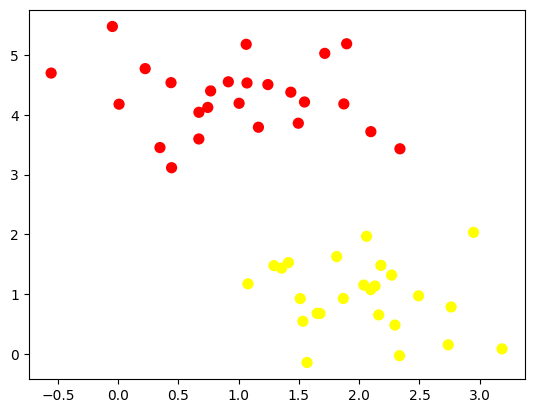

In [2]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

### Langkah 3 - Ilustrasi Garis Pemisah
Untuk membuat model klasifikasi diperlukan garis pemisah dari dua himpunan data. Namun, masih ada kasus di mana garis pemisah yang mungkin lebih dari satu. Banyaknya garis pemisah menunjukkan adanya beberapa kemungkinan kategori untuk data baru. Data baru 'x' diletakkan pada posisi berbeda dari dua himpunan sebelumnya sehingga tidak masuk ke kategori manapun secara jelas.

### Langkah 4 - Ilustrasi Margin


(-1.0, 3.5)

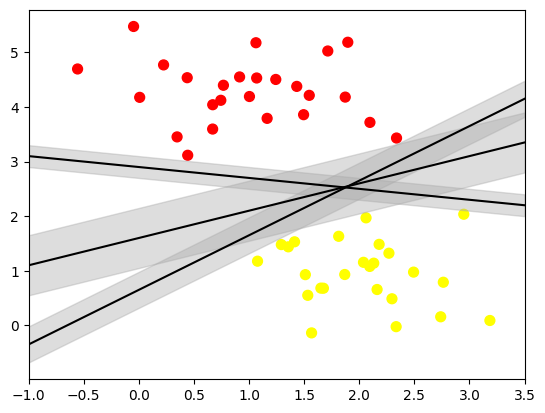

In [3]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)


### Langkah 5 - Fitting Model
Model SVM dilatih menggunakan kernel linier.

In [4]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

Fungsi bantu untuk visualisasi hasil fit model:

In [5]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

Plotting dengan fungsi yang telah dibuat:

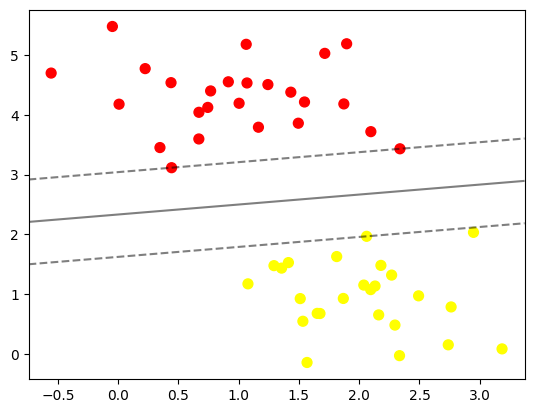

In [6]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

Titik data yang menyentuh garis margin disebut *support vector*. Untuk melihatnya:

In [7]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

Hasil fitting hanya ditentukan oleh posisi support vector. Data lain yang jauh dari margin dan berada di area yang tepat tidak memodifikasi fitting karena tidak berkontribusi pada loss function. Untuk memahaminya, dibandingkan penggunaan 60 dan 120 data awal:

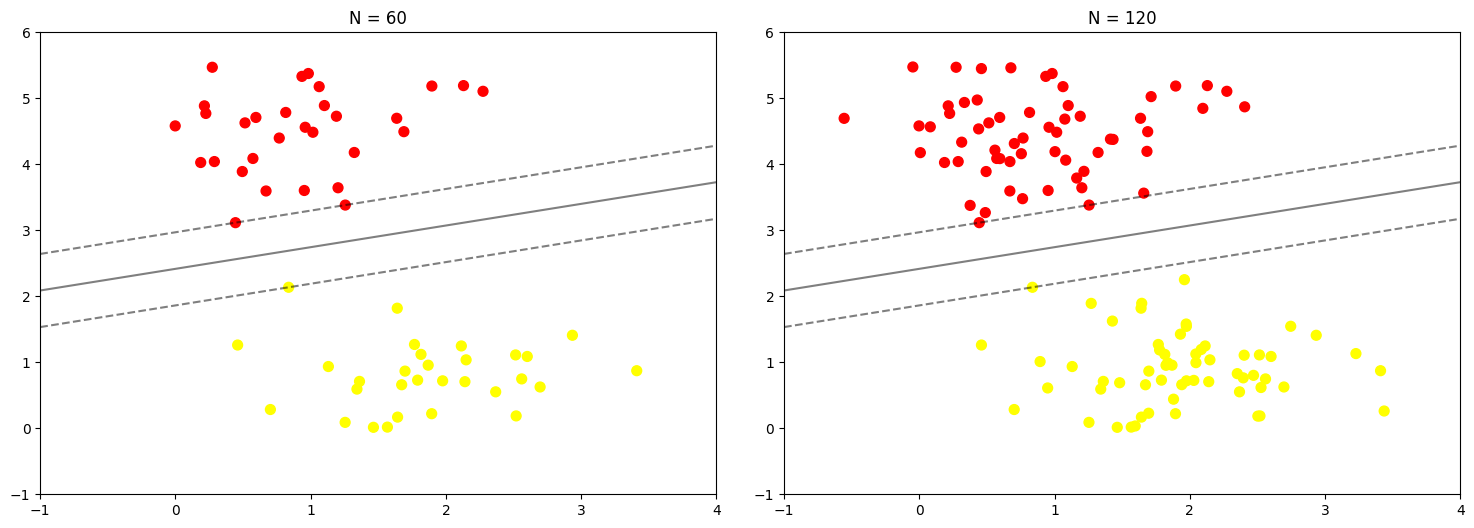

In [8]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

Perubahan jumlah data tidak mempengaruhi model yang digunakan. Ilustrasi interaktif (instal `ipywidgets` jika belum: `!pip install ipywidgets`):

In [9]:
# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

# Praktikum 2
## Klasifikasi SVM dengan Data Dummy Non-Linier


### Langkah 1 - Ilustrasi Data Non-Linier


**Langkah 1a - Import Library**

In [10]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

**Langkah 1b - Buat Kembali Fungsi Plotting**

In [11]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

**Langkah 1c - Buat Data Dummy Non-Linier**

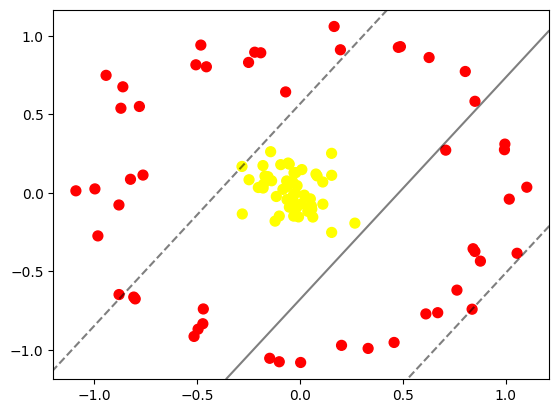

In [12]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

Tidak ditemukan garis pemisah linier yang mampu memisahkan data. Diperlukan proyeksi lain, yaitu proyeksi berbasis radial:

In [13]:
r = np.exp(-(X ** 2).sum(1))

Karena proyeksi radial tidak cukup dengan model 2D, visualisasi diubah menjadi 3D. (NB: butuh `ipywidgets`; mungkin tidak berjalan di Google Colab.)

In [14]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-0.24672609,  0.0834009 ],
       [ 0.80365484,  0.77277763],
       [ 0.0509689 , -0.03828413],
       [-0.0316154 , -0.01406016],
       [ 0.20254718, -0.97113289],
       [ 1.10249728,  0.03583469],
       [-0.49430574, -0.86815252],
       [ 0.61221014, -0.7708973 ],
       [ 0.06294128, -0.15411333],
       [ 0.66977934, -0.76315154],
       [-0.82259658,  0.08640082],
       [-0.94121853,  0.74829101],
       [-0.99541437,  0.02520732],
       [-0.51390747, -0.91425261],
       [-0.20153067,  0.03399616],
       [ 0.70866497,  0.27190423],
       [-0.01539828, -0.09386057],
       [ 1.01732273, -0.04013388],
       [ 1.05527068, -0.38474808],
       [ 0.05584148, -0.08253727],
       [ 0.15462437,  0.11176191],
       [-0.12021954, -0.18011906],
       [-0.85971524,  0.67515896],
       [ 0.05806365, -0.10319026],
       [-0.02975766, -0.14815596],
       [-0.87818417, -0.64759298],
       [-0.21908968,  0.89554299],
       [-0.11429968, -0.02314589],
       [ 0.16656715,  1.05939441],
       [ 0.02176285, -0.01453895],
       [-0.77937483,  0.55001548],
       [-0.28097151,  0.16812072],
       [ 0.83684745, -0.74092132],
       [-0.02836669,  0.12786543],
       [ 0.47855233,  0.92643998],
       [-0.09269183,  0.1796656 ],
       [-0.79966312, -0.67520172],
       [-0.09988406, -0.14768245],
       [-0.0999632 , -1.07560622],
       [-1.08782021,  0.01289123],
       [ 0.11194725, -0.07212469],
       [-0.27958192, -0.13443394],
       [ 0.00775583, -0.07036484],
       [ 0.26741581, -0.19285734],
       [ 0.85072622,  0.58294478],
       [-0.16933708,  0.10646926],
       [-0.48088595,  0.94098841],
       [ 0.19713688,  0.9110634 ],
       [ 0.7631251 , -0.61944941],
       [-0.05705965,  0.18977975],
       [ 0.0039624 , -1.08016366],
       [ 0.15454824, -0.25197106],
       [ 0.9938944 ,  0.27487192],
       [-0.24904304,  0.83049798],
       [-0.14181264,  0.26199095],
       [-0.06093086,  0.04081371],
       [-0.0623213 , -0.04303794],
       [-0.00635582, -0.15315213],
       [ 0.84146876, -0.35588745],
       [-0.13711528,  0.07694302],
       [ 0.85040336, -0.37348429],
       [-0.03441823, -0.03677624],
       [ 0.15424918,  0.25163824],
       [-0.98099484, -0.27413897],
       [ 0.03859432, -0.11768922],
       [ 0.00971676,  0.1481848 ],
       [-0.50490913,  0.81534678],
       [-0.0347501 ,  0.07049401],
       [-0.14627009, -1.05350896],
       [-0.17906315,  0.17362173],
       [-0.06895056,  0.64265147],
       [-0.45399393,  0.80270848],
       [-0.87872589, -0.07722792],
       [-0.15478394,  0.10304791],
       [ 0.45784815, -0.95269595],
       [ 0.62786959,  0.86169584],
       [-0.05087446, -0.09104758],
       [ 0.33169322, -0.99063365],
       [-0.18981037,  0.89184102],
       [-0.76185878,  0.11320724],
       [-0.0214275 , -0.00123403],
       [-0.08229746,  0.02217597],
       [-0.86914574,  0.5387851 ],
       [ 0.99600608,  0.31039438],
       [-0.03901663, -0.05315791],
       [ 0.87714812, -0.43478539],
       [ 0.11134996,  0.06915916],
       [-0.80668517, -0.66363873],
       [ 0.04257927, -0.09703006],
       [-0.46889708, -0.73929449],
       [-0.01940641,  0.12897548],
       [ 0.07824193,  0.11974197],
       [-0.05141387,  0.18289368],
       [-0.47116495, -0.83350295],
       [-0.17690254,  0.05404707],
       [-0.06403118,  0.07585958],
       [ 0.08393025,  0.10799968],
       [ 0.48851162,  0.93094355],
       [-0.01330523,  0.04582388],
       [-0.1783719 ,  0.03076111]]), y=array([1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1,
       0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1]))>

### Langkah 2 - Fitting Model
Memproyeksikan N titik data ke dimensi N menambah beban komputasi. Untuk mengatasinya digunakan kernel *radial basis function* (RBF) pada Scikit-Learn:

In [15]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

Plot hasil decision boundaries kernel RBF:

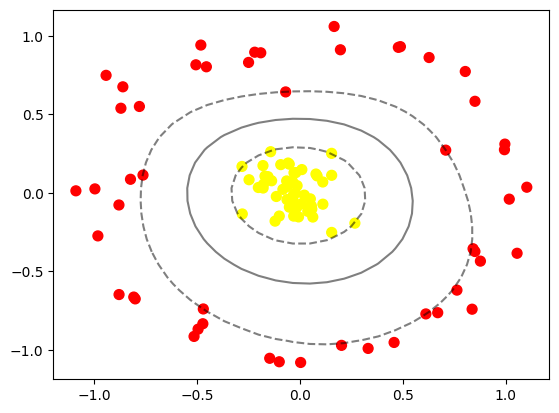

In [16]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')

# Praktikum 3
## SVM Data Overlapping


### Langkah 1 - Import Library dan Buat Fungsi Plotting

In [17]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [18]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### Langkah 2 - Buat Data Dummy

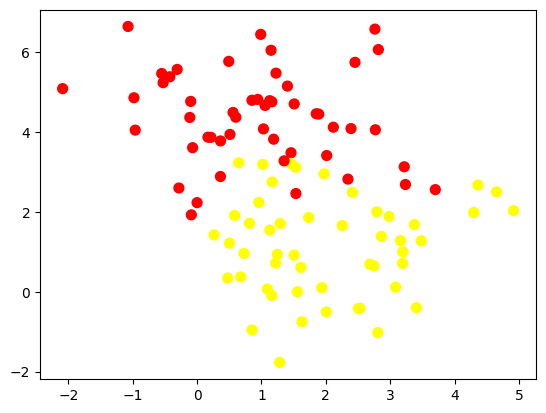

In [19]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

### Langkah 3 - Analisis Dampak Tuning
Teknik penghalusan margin pada SVM memasukkan beberapa titik data ke dalam margin agar fitting lebih baik. Ketebalan margin dikelola oleh parameter tuning **C**. Contoh berikut menunjukkan dampak perubahan C pada hasil fitting:

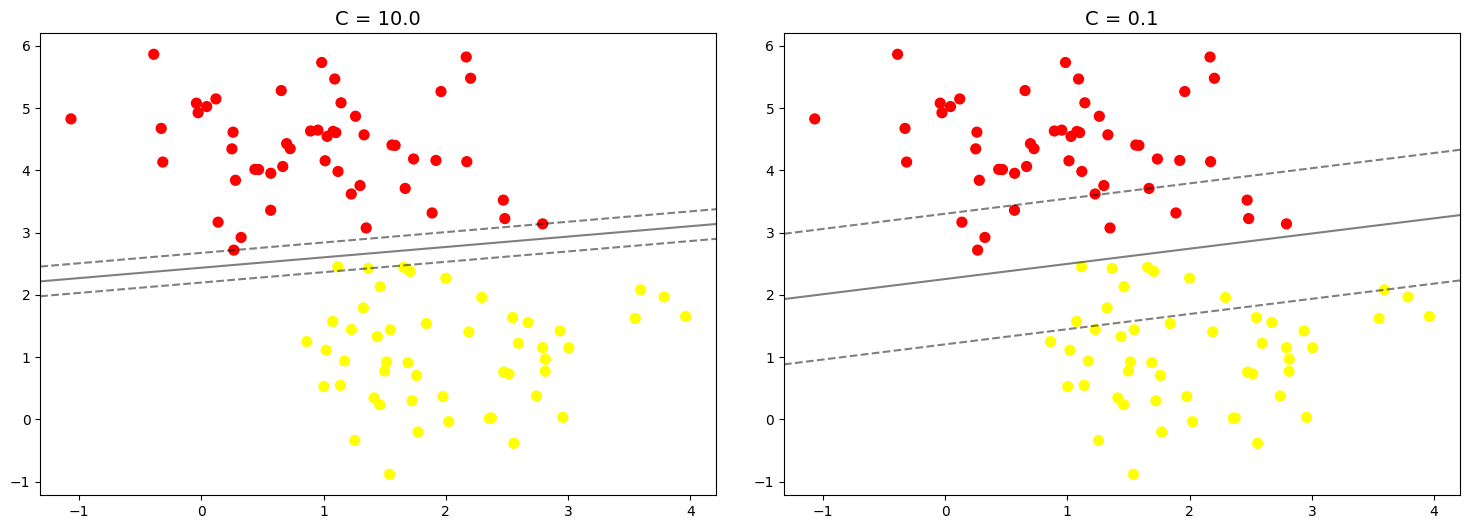

In [20]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

Nilai optimal C bergantung pada setiap dataset (melalui cross-validation atau prosedur serupa).

# Praktikum 4
## Klasifikasi Citra Wajah

### Pengantar


### Langkah 0 - Unduh Dataset

In [1]:
	from sklearn.datasets import fetch_lfw_people
	faces = fetch_lfw_people(min_faces_per_person=60)
	print(faces.target_names)
	print(len(faces.target_names))
	print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


### Langkah 1 - Inspeksi Citra Wajah

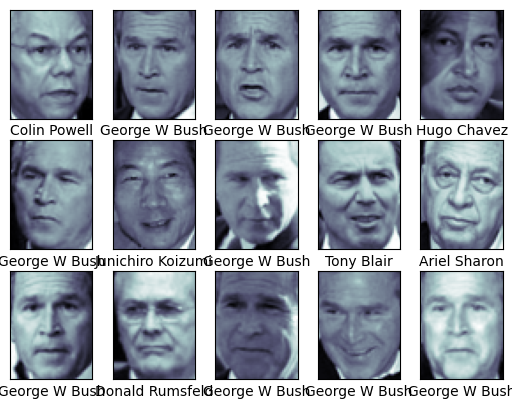

In [3]:
# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

### Langkah 2 - Pra Pengolahan Data
Pra pengolahan menggunakan *Principal Component Analysis* (PCA), yaitu reduksi dimensi yang memproyeksikan fitur berdimensi banyak ke *principal component* yang dianggap penting.

In [4]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

### Langkah 3 - Split Data

In [5]:
# pemisahan data training dan data testing

from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

### Langkah 4 - Pembuatan Model + Tuning
Hyperparameter tuning dengan `GridSearchCV`, yang menguji kombinasi hyperparameter satu per satu (mudah, tetapi memakan waktu dan komputasi tinggi).

In [8]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 2min 13s, sys: 209 ms, total: 2min 14s
Wall time: 1min 45s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


Contoh hasil pada jobsheet: `{'svc__C': 5, 'svc__gamma': 0.001}` dengan skor 0.8289 (akurasi 82.88%). Model terbaik digunakan untuk prediksi:

In [9]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

### Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

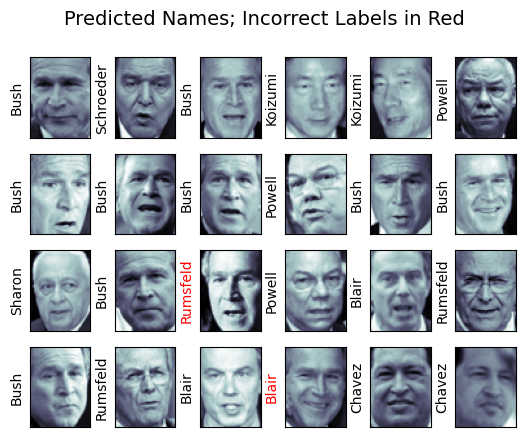

In [10]:
# hasil label pada data testing

fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

### Langkah 6 - Cek Performansi
Performansi diukur dengan `classification_report` dan `confusion_matrix`.

In [11]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Text(113.92222222222219, 0.5, 'predicted label')

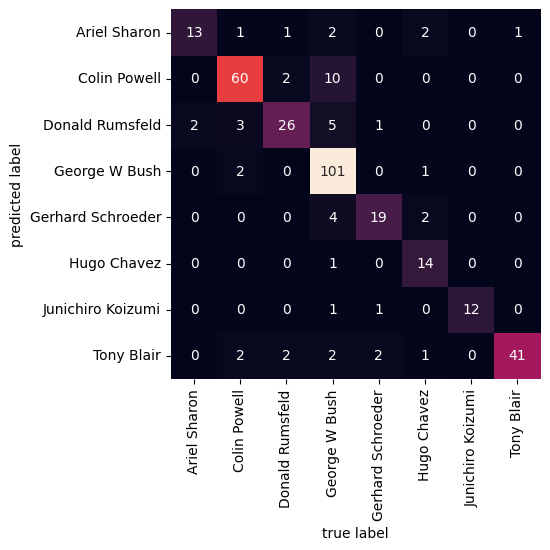

In [12]:
# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')

# Praktikum 5
## Klasifikasi Citra Siang dan Malam


### Langkah 0 - Import Library

In [10]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd
import os

train_dir = "images/training/"
test_dir = "images/test/"

def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        if not dir.is_dir():
            continue
        label = dir.name
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if img is not None:
                img_list.append((img, label))

    return img_list

train_img = load_dataset(train_dir)
print("Jumlah data training:", len(train_img))

Jumlah data training: 240


### Langkah 1 - Load Data dan Visualisasikan

In [11]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 67
(458, 800, 3)


In [13]:
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Shape	: (469, 640, 3)
Label	: night


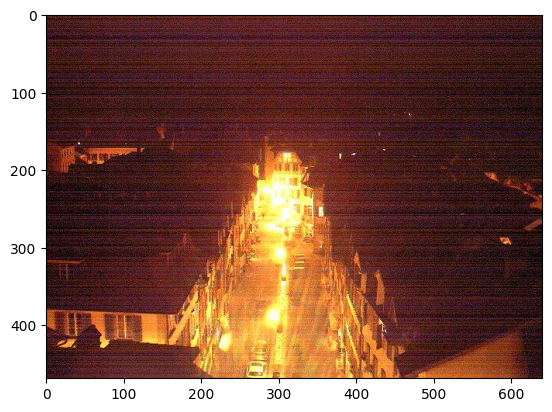

In [14]:
random_img_viz(train_img)

### Langkah 3 - Pra Pengolahan Data
Dua proses utama: standardisasi ukuran gambar dan *encoding* label.

In [15]:
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img

In [16]:
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0

    if(label == 'day'):
        num_val = 1

    return num_val

In [17]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [18]:
train_std_img_list = preprocess(train_img)

In [19]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 120
(600, 1100, 3)


### Langkah 4 - Ekstraksi Fitur


In [20]:
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 179
Avg Brighness: 133.3584


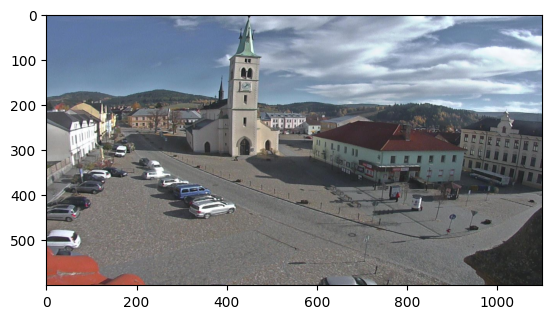

In [21]:
# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)

### Langkah 5 - Klasifikasi dengan Metode Threshold


In [22]:
def predict_label(img, threshold):
    # Computer average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Image 136
Actual label: 1
Predicted label: 0


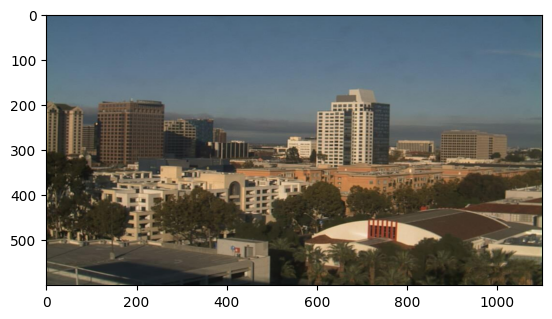

In [23]:
# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

### Langkah 6 - Evaluasi Manual


In [24]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [25]:
# Evaluate on train data
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [26]:
# Evaluate on test data

# Load test data
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Predict
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


## Klasifikasi dengan SVM
Menentukan threshold secara manual kurang efektif karena harus tepat, sehingga digunakan model SVM. Langkahnya serupa; perbedaan dimulai dari langkah ke-4.

### Langkah 4 Alternatif - Membuat Feature Vectors
Semua nilai rata-rata kecerahan ditabulasikan dalam tabel dengan kolom fitur dan label (Pandas dataframe).

In [27]:
# Create function to extract feature for every images and stored in tabular data
# Stored in Pandas dataframe
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
        img_label = img[1] # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)

    # Stack data in columcular way
    data = np.column_stack((avg_list, labels))
    # Create a Pandas dataframe
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [28]:
# Extract feature on train data
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,26.946276,0.0
1,114.386045,0.0
2,36.167309,0.0
3,89.905798,0.0
4,48.713038,0.0


In [29]:
# Do the same thing on test data
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,37.642245,0.0
1,38.777894,0.0
2,26.358703,0.0
3,41.211485,0.0
4,53.467780,0.0


### Langkah 5 - Buat Model SVM
Model SVM dengan kernel RBF (default) menggunakan scikit-learn.

In [30]:
# import requied library
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

SVC()

### Langkah 6 - Evaluasi

In [31]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


**Tugas Praktikum**

tugas 1

In [32]:
from google.colab import files
uploaded = files.upload()   # pilih voice.csv

Saving voice.csv to voice.csv


In [33]:
import pandas as pd

df = pd.read_csv("voice.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(3168, 21)
['meanfreq', 'sd', 'median', 'Q25', 'Q75', 'IQR', 'skew', 'kurt', 'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx', 'label']


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

X = df.drop(columns=["label"])
y = df["label"]

splits = {"70:30": 0.30, "80:20": 0.20}
kernels = ["linear", "poly", "rbf"]

hasil = []
for nama_split, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    for k in kernels:
        model = make_pipeline(StandardScaler(), SVC(kernel=k))
        model.fit(X_train, y_train)
        acc_train = accuracy_score(y_train, model.predict(X_train))
        acc_test = accuracy_score(y_test, model.predict(X_test))
        hasil.append([nama_split, k, acc_train, acc_test])

tabel = pd.DataFrame(hasil, columns=["Split", "Kernel", "Akurasi Train", "Akurasi Test"])
tabel

,Split,Kernel,Akurasi Train,Akurasi Test
0,70:30,linear,0.972034,0.978970
1,70:30,poly,0.966622,0.960042
2,70:30,rbf,0.983762,0.983176
3,80:20,linear,0.976717,0.974763
4,80:20,poly,0.968035,0.955836
5,80:20,rbf,0.983820,0.982650


In [35]:
tabel.pivot(index="Kernel", columns="Split", values="Akurasi Test").round(4)

Split,70:30,80:20
Kernel,,
linear,0.9790,0.9748
poly,0.9600,0.9558
rbf,0.9832,0.9826


tugas 2

In [36]:
from pathlib import Path
import matplotlib.image as mpimg
import numpy as np
import cv2
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

def load_dataset(img_dir):
    img_list = []
    for d in Path(img_dir).glob('*'):
        if not d.is_dir():
            continue
        for f in d.glob('*.jpg'):
            img_list.append((mpimg.imread(f), d.name))
    return img_list

data = load_dataset("images/training/") + load_dataset("images/test/")
print("Total gambar:", len(data))   # 400

Total gambar: 400


In [37]:
def hist_feature(img, bins=32):
    img = cv2.resize(img, (1100, 600))
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    fitur = []
    for ch, rng in zip(range(3), [[0, 180], [0, 256], [0, 256]]):
        hist = cv2.calcHist([hsv], [ch], None, [bins], rng).flatten()
        fitur.append(hist / hist.sum())
    return np.concatenate(fitur)

X = np.array([hist_feature(img) for img, _ in data])
y = np.array([1 if label == 'day' else 0 for _, label in data])
print(X.shape)   # (400, 96)

(400, 96)


In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

base = SVC(kernel='rbf').fit(X_train, y_train)
print("Default  train:", accuracy_score(y_train, base.predict(X_train)))
print("Default  test :", accuracy_score(y_test, base.predict(X_test)))

Default  train: 1.0
Default  test : 1.0


In [39]:
pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
param_grid = {
    'svc__C': [0.1, 1, 10, 100, 1000],
    'svc__gamma': ['scale', 0.0001, 0.001, 0.01, 0.1, 1]
}

gs = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy')
gs.fit(X_train, y_train)

print("Parameter terbaik:", gs.best_params_)
print("Akurasi CV terbaik:", gs.best_score_)
print("Tuned  train:", accuracy_score(y_train, gs.predict(X_train)))
print("Tuned  test :", accuracy_score(y_test, gs.predict(X_test)))

Parameter terbaik: {'svc__C': 10, 'svc__gamma': 0.001}
Akurasi CV terbaik: 1.0
Tuned  train: 1.0
Tuned  test : 1.0
